# Shift equivariance

The property a convolution has and a graph network has to be given: convolve
then shift, or shift then convolve, and away from the edges you get the same
picture. The cell at the end checks it by comparing two windows of the two
results.

**Run this after the lesson.** It needs the `gnn` package group, and the photo
next to this file. Nothing else — no Neo4j, no model, no download.

**`convolve` takes about 22 seconds and 3 GB each time it is called, and it is
called twice.** It is a double Python loop that builds all 12,178,660 regions
of a 4032x3024 photo in a list before touching any of them — which is the slow,
literal way to write a convolution, and the readable one. Measured 27/11/2026.

In [1]:
import numpy as np
from skimage import color, io
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle

In [2]:
# helper functions to apply convolution and shift (translation)

def convolve(img, filter):

  # shape of the filter
  flt_size = filter.shape[0]

  # height and width of the input image
  h, w = img.shape

  # output initialization: height x width x channels (1 for gray scale)
  out = np.zeros((h - flt_size + 1, w - flt_size + 1, 1))

  # initialize image regions on which we will apply the filter
  regions = []
  for i in range(h - flt_size + 1):
    for j in range(w - flt_size + 1):
      im_region = img[i:(i + flt_size), j:(j + flt_size)]
      regions.append((im_region, i, j))

  # convolve the image with the filter and fill the previously created regions
  for im_regions, i, j in regions:
     out[i, j] = np.sum(im_regions * filter, axis=(0,1))

  return out

def shift(img, v=(5, 5)):
  return np.roll(img, v, axis=(0, 1))

In [3]:
# convolution filter (or kernel)
filter = np.array([[1, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]])

# Shift equivariance on a real image

Shape (3024, 4032, 3)


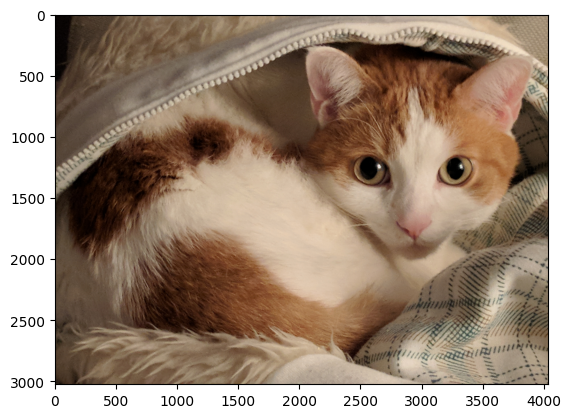

In [4]:
# load image
img = io.imread("minuzzo.jpg")
print("Shape", img.shape)
plt.imshow(img)

Shape (3024, 4032)


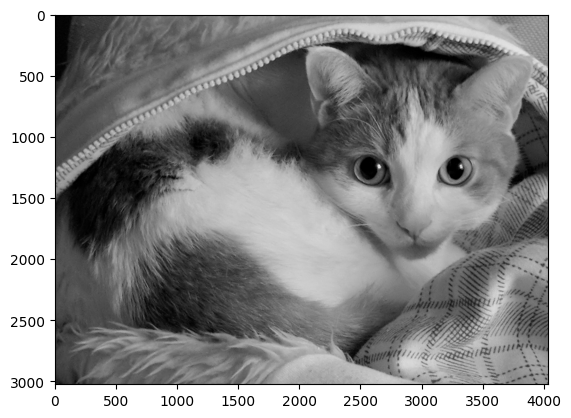

In [5]:
# from coloured to grayscale
img = color.rgb2gray(img)
print("Shape", img.shape)
plt.imshow(img, cmap='gray')

Shape (3022, 4030, 1)


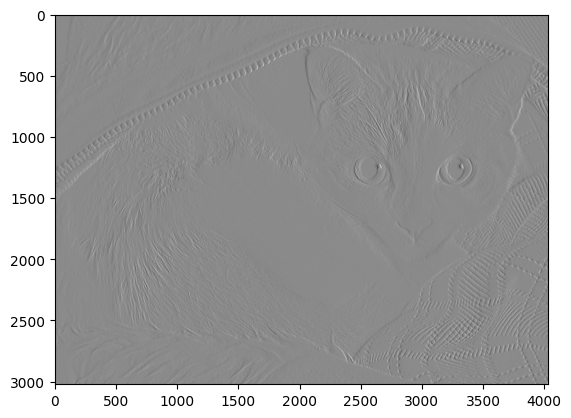

In [6]:
# apply the convolution to the grayscale image
convolved = convolve(img, filter)
print("Shape", convolved.shape)
plt.imshow(convolved, cmap="gray")

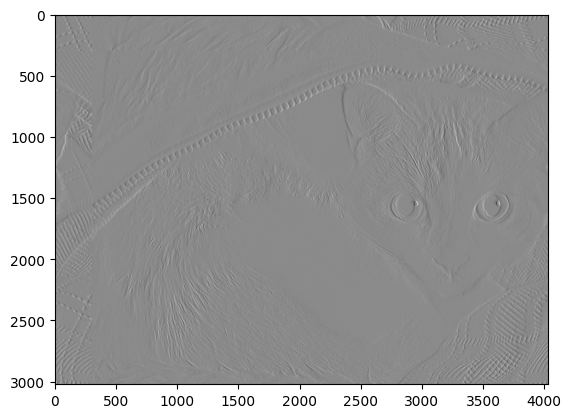

In [7]:
# shift the convolved image
shift_convolved = shift(convolved, v=(300,300))
plt.imshow(shift_convolved, cmap="gray")

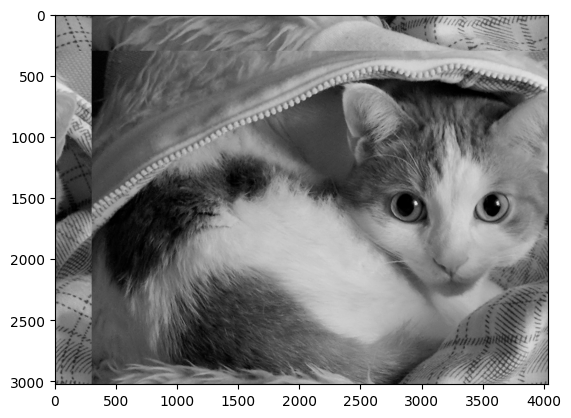

In [8]:
# shift of the grayscale image
shifted = shift(img, v=(300,300))
plt.imshow(shifted, cmap="gray")

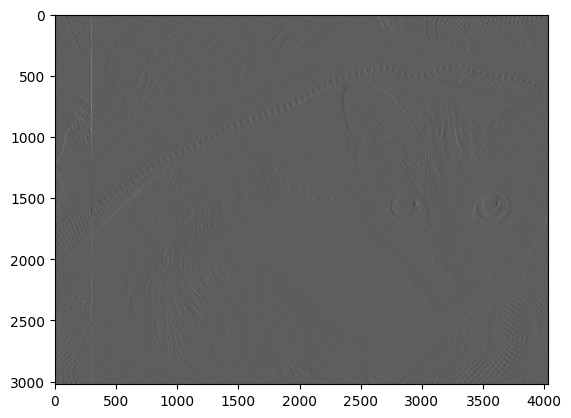

In [9]:
# convolve the shifted image
convolve_shifted = convolve(shifted, filter)
plt.imshow(convolve_shifted, cmap="gray")

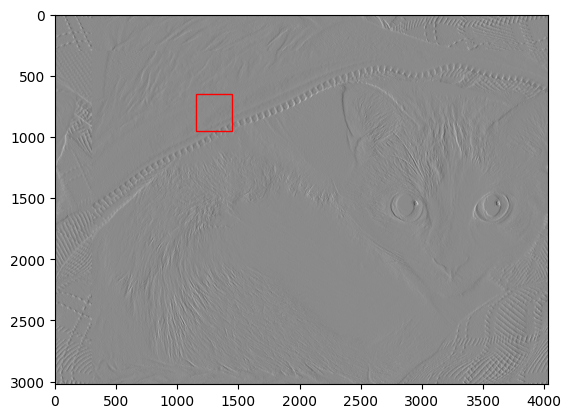

In [10]:
# draw red rect on the first image (convolution + shift)
plt.imshow(shift_convolved, cmap="gray")
ax = plt.gca()
rect = Rectangle((1150,650),300, 300,linewidth=1,edgecolor='r',facecolor='none')
ax.add_patch(rect)

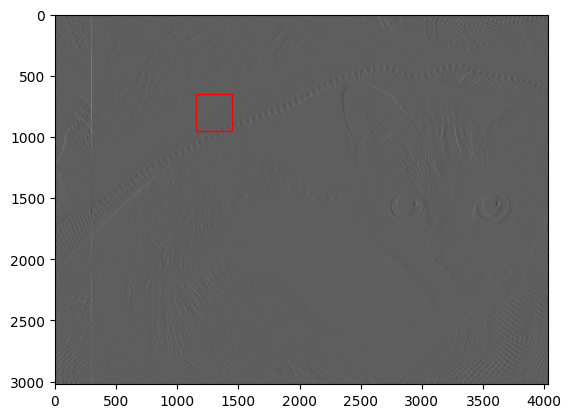

In [11]:
# draw red rect on the second image (shift + convolutio)
plt.imshow(convolve_shifted, cmap="gray")
ax = plt.gca()
rect = Rectangle((1150,650),300, 300,linewidth=1,edgecolor='r',facecolor='none')
ax.add_patch(rect)

## The two windows, and why one of them disagrees

The next two cells compare the same window of *convolve then shift* and *shift
then convolve*. The first window sits in the middle of the picture and the
second in the corner.

In [12]:
np.all(shift_convolved[1150:1450, 650:950]  == convolve_shifted[1150:1450, 650:950])

np.True_

In [13]:
np.all(shift_convolved[0:300, 0:300]  == convolve_shifted[0:300, 0:300])

np.False_

**True in the middle, False in the corner, and both are the right answer.**
Equivariance is a statement about the interior: shifting and convolving commute
wherever the filter has all nine of its pixels. In the corner they cannot,
because `shift` here is `np.roll`, which wraps the picture around — so one order
convolves pixels that were neighbours and the other convolves pixels that came
from the opposite edge.

Which is the thing to carry to a graph. A convolution gets shift equivariance
from the grid it runs on, for free and only away from the boundary. A graph has
no grid and no natural order of nodes at all, so the equivalent property —
permutation equivariance — is not free: it has to be built into the layer, by
aggregating neighbours with a function that does not care what order they arrive
in. That is what the other notebook here unit-tests, and what `aggr='add'` is.